# STEP 2 : แปลง JSON (AnyLabeling) → YOLO txt
**ไฟล์คู่กัน:** `02_anylabeling_to_yolo.py`

YOLO ไม่อ่าน JSON แต่ต้องการ **ไฟล์ .txt 1 ไฟล์ต่อ 1 ภาพ** และพิกัดต้อง **normalize เป็น 0–1** (หารด้วยความกว้าง/สูงของภาพ)

| แบบ | 1 บรรทัด = 1 วัตถุ |
|---|---|
| Rectangle | `class  x_center  y_center  width  height` |
| Polygon | `class  x1 y1  x2 y2  x3 y3 ...` |

In [1]:
# ===== ตั้งค่าเริ่มต้น (ทุก notebook ใช้เหมือนกัน) =====
import os, sys, json
from pathlib import Path
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # กัน error OMP บน Windows

# notebook อยู่ใน final_dip/scripts/  ->  ย้ายไปทำงานที่ final_dip/ (path ทุกอย่างอ้างอิงจากที่นี่)
ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
os.chdir(ROOT)
CLASSES = ["airplane", "boat", "car", "motorcycle"]
print("ทำงานที่:", ROOT)
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

# โหลดฟังก์ชันจากไฟล์ .py ของขั้นนี้มาใช้ (ชื่อไฟล์ขึ้นต้นด้วยตัวเลข เลย import ตรง ๆ ไม่ได้)
import importlib.util
def load_script(name):
    spec = importlib.util.spec_from_file_location(name, f"scripts/{name}.py")
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

step2 = load_script("02_anylabeling_to_yolo")

ทำงานที่: C:\code\ImageProcessing\yolo\yolo_lab\final_dip


## 2.1 แปลง Rectangle ทีละขั้น (คำนวณให้ดูด้วยมือ)

In [2]:
data = json.loads(Path("datasets/anylabeling_rectangle/car/car_001.json").read_text(encoding="utf-8"))
W, H = data["imageWidth"], data["imageHeight"]
shape = data["shapes"][0]
(x1, y1), (x2, y2) = shape["points"]
print(f"ขนาดภาพ             W = {W}, H = {H}")
print(f"AnyLabeling (pixel)  มุมซ้ายบน = ({x1}, {y1})   มุมขวาล่าง = ({x2}, {y2})")

# 1) หาจุดกึ่งกลาง และ ความกว้าง/สูง (pixel)
xc, yc = (x1 + x2) / 2, (y1 + y2) / 2
w, h = x2 - x1, y2 - y1
print(f"จุดกึ่งกลาง (pixel)    xc = {xc:.1f}, yc = {yc:.1f}   w = {w:.1f}, h = {h:.1f}")

# 2) normalize : หารด้วยขนาดภาพ
print(f"normalize            xc = {xc/W:.6f}, yc = {yc/H:.6f}, w = {w/W:.6f}, h = {h/H:.6f}")

class_id = CLASSES.index(shape["label"])
print(f"\nบรรทัด YOLO (คำนวณเอง)  : {class_id} {xc/W:.6f} {yc/H:.6f} {w/W:.6f} {h/H:.6f}")

# เทียบกับฟังก์ชันในไฟล์ .py
objs = step2.group_objects(data["shapes"])
print("บรรทัด YOLO (จากสคริปต์) :", step2.object_to_yolo_line(*objs[0], W, H, "rect"))

ขนาดภาพ             W = 500, H = 343
AnyLabeling (pixel)  มุมซ้ายบน = (96.7, 85.2)   มุมขวาล่าง = (306.9, 297.0)
จุดกึ่งกลาง (pixel)    xc = 201.8, yc = 191.1   w = 210.2, h = 211.8
normalize            xc = 0.403600, yc = 0.557143, w = 0.420400, h = 0.617493

บรรทัด YOLO (คำนวณเอง)  : 2 0.403600 0.557143 0.420400 0.617493
บรรทัด YOLO (จากสคริปต์) : 2 0.403600 0.557143 0.420400 0.617493


## 2.2 แปลง Polygon ทีละขั้น

In [3]:
data = json.loads(Path("datasets/anylabeling_polygon/car/car_001.json").read_text(encoding="utf-8"))
W, H = data["imageWidth"], data["imageHeight"]
pts = data["shapes"][0]["points"]
print("จำนวนจุด :", len(pts))
for x, y in pts[:3]:
    print(f"  ({x:7.1f}, {y:7.1f})  ->  ({x/W:.6f}, {y/H:.6f})")
print("  ...")
objs = step2.group_objects(data["shapes"])
line = step2.object_to_yolo_line(*objs[0], W, H, "poly")
print("\nบรรทัด YOLO :", line[:120], "...")
print("จำนวนตัวเลขในบรรทัด =", len(line.split()), "(1 class +", len(pts), "จุด x 2)")

จำนวนจุด : 51
  (   98.2,   290.9)  ->  (0.196400, 0.848105)
  (   96.7,   215.7)  ->  (0.193400, 0.628863)
  (   96.7,   191.9)  ->  (0.193400, 0.559475)
  ...

บรรทัด YOLO : 2 0.196400 0.848105 0.193400 0.628863 0.193400 0.559475 0.230200 0.543732 0.242400 0.499125 0.256400 0.494752 0.259400 0 ...
จำนวนตัวเลขในบรรทัด = 103 (1 class + 51 จุด x 2)


## 2.3 วัตถุที่ถูกบังจนแยกเป็นหลายชิ้น (group_id)
YOLO รับได้ **1 polygon ต่อ 1 วัตถุ** ถ้าวัตถุถูกบัง (เช่น โดนเสาบัง) จะมีหลายชิ้นที่ `group_id` เดียวกัน
สคริปต์จะเชื่อมทุกชิ้นเป็นเส้นเดียวด้วย `merge_multi_segment` ของ ultralytics

ไฟล์: airplane_001.json
  shape: airplane   group_id = 0  จุด = 15
  shape: airplane   group_id = 0  จุด = 10
  shape: airplane   group_id = None  จุด = 70
  shape: airplane   group_id = None  จุด = 33

หลังรวม group -> 3 วัตถุ : [('airplane', '2 ชิ้น'), ('airplane', '1 ชิ้น'), ('airplane', '1 ชิ้น')]


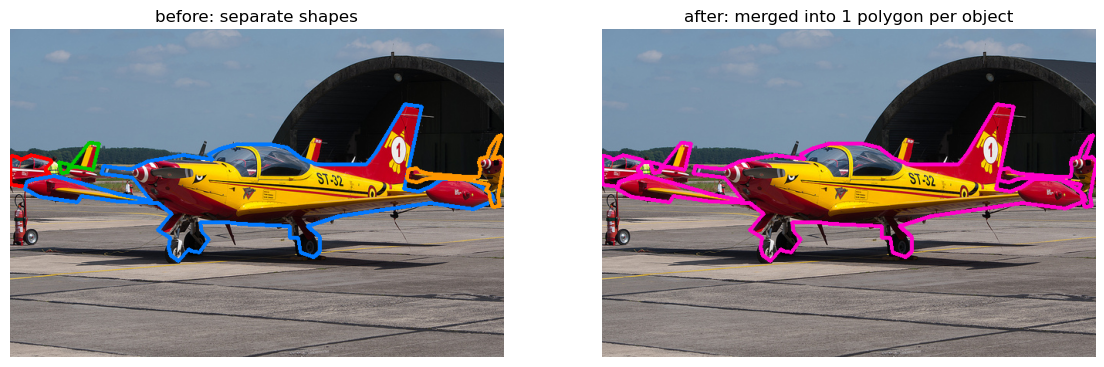

In [4]:
# หาไฟล์ตัวอย่างที่มี group_id
example = None
for j in sorted(Path("datasets/anylabeling_polygon").rglob("*.json")):
    d = json.loads(j.read_text(encoding="utf-8"))
    if any(s.get("group_id") is not None for s in d["shapes"]):
        example = (j, d); break

j, d = example
print("ไฟล์:", j.name)
for s in d["shapes"]:
    print(f"  shape: {s['label']:<10} group_id = {s['group_id']}  จุด = {len(s['points'])}")
objs = step2.group_objects(d["shapes"])
print("\nหลังรวม group ->", len(objs), "วัตถุ :", [(lb, f"{len(parts)} ชิ้น") for lb, parts in objs])

im = cv2.cvtColor(cv2.imread(str(j.with_suffix(".jpg"))), cv2.COLOR_BGR2RGB)
before, after = im.copy(), im.copy()
colors = [(255, 0, 0), (0, 200, 0), (0, 120, 255), (255, 150, 0)]
for i, s in enumerate(d["shapes"]):
    cv2.polylines(before, [np.array(s["points"], np.int32).reshape(-1, 1, 2)], True, colors[i % 4], 3)
for lb, parts in objs:
    line = step2.object_to_yolo_line(lb, parts, d["imageWidth"], d["imageHeight"], "poly")
    p = (np.array(line.split()[1:], float).reshape(-1, 2) * [d["imageWidth"], d["imageHeight"]]).astype(np.int32)
    cv2.polylines(after, [p.reshape(-1, 1, 2)], True, (255, 0, 200), 3)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(before); ax[0].set_title("before: separate shapes"); ax[0].axis("off")
ax[1].imshow(after); ax[1].set_title("after: merged into 1 polygon per object"); ax[1].axis("off")
plt.show()

## 2.4 รันแปลงทั้ง dataset + แบ่ง train / val / test (70 / 20 / 10)

In [5]:
!{sys.executable} scripts/02_anylabeling_to_yolo.py --mode rect --src datasets/anylabeling_rectangle --dst datasets/yolo_rect


YOLO dataset (rect) -> datasets\yolo_rect
class          train     val    test   total
airplane         135      43      18     196
boat             153      48      35     236
car              161      49      28     238
motorcycle       154      37      16     207


In [6]:
!{sys.executable} scripts/02_anylabeling_to_yolo.py --mode poly --src datasets/anylabeling_polygon --dst datasets/yolo_poly


YOLO dataset (poly) -> datasets\yolo_poly
class          train     val    test   total
airplane         135      43      18     196
boat             153      48      35     236
car              161      49      28     238
motorcycle       154      37      16     207


In [7]:
# โครงสร้างโฟลเดอร์ที่ได้ (แบบเดียวกับ dataset/box ใน lab)
for mode in ["rect", "poly"]:
    for split in ["train", "val", "test"]:
        n_img = len(list(Path(f"datasets/yolo_{mode}/{split}/images").glob("*.jpg")))
        n_lbl = len(list(Path(f"datasets/yolo_{mode}/{split}/labels").glob("*.txt")))
        print(f"datasets/yolo_{mode}/{split:<5}  images = {n_img:>3}   labels = {n_lbl:>3}")

datasets/yolo_rect/train  images = 420   labels = 420
datasets/yolo_rect/val    images = 120   labels = 120
datasets/yolo_rect/test   images =  60   labels =  60
datasets/yolo_poly/train  images = 420   labels = 420
datasets/yolo_poly/val    images = 120   labels = 120
datasets/yolo_poly/test   images =  60   labels =  60


## 2.5 ตรวจสอบ : วาด label YOLO กลับลงบนภาพ ต้องตรงกับวัตถุ

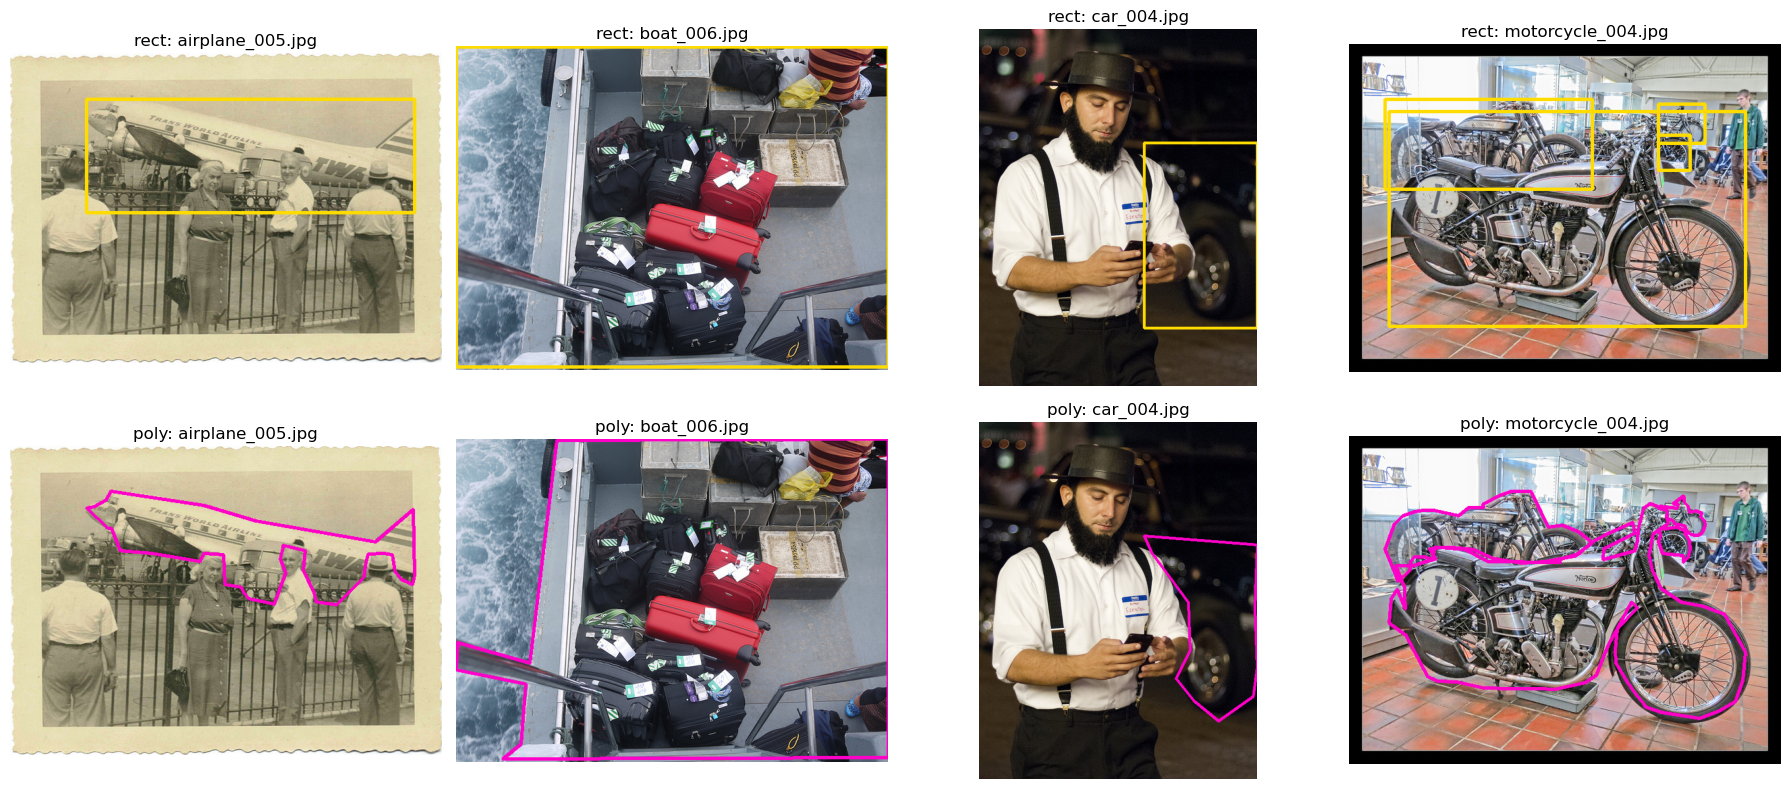

In [8]:
def draw_yolo(img_path, mode):
    im = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lbl = Path(str(img_path).replace("images", "labels")).with_suffix(".txt")
    for ln in lbl.read_text().split("\n"):
        if not ln.strip():
            continue
        v = list(map(float, ln.split()))[1:]
        if mode == "rect":
            xc, yc, bw, bh = v
            cv2.rectangle(im, (int((xc - bw/2) * w), int((yc - bh/2) * h)),
                              (int((xc + bw/2) * w), int((yc + bh/2) * h)), (255, 220, 0), 3)
        else:
            p = (np.array(v).reshape(-1, 2) * [w, h]).astype(np.int32)
            cv2.polylines(im, [p.reshape(-1, 1, 2)], True, (255, 0, 200), 3)
    return im

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for c, cls in enumerate(CLASSES):
    for r, mode in enumerate(["rect", "poly"]):
        f = sorted(Path(f"datasets/yolo_{mode}/train/images").glob(f"{cls}_*.jpg"))[3]
        axes[r, c].imshow(draw_yolo(f, mode)); axes[r, c].set_title(f"{mode}: {f.name}"); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## 2.6 ไฟล์ yaml บอก YOLO ว่า dataset อยู่ไหน
⚠️ ต้องเป็น `names:` (มี s) ถ้าพิมพ์ `name:` YOLO จะไม่รู้ชื่อคลาส (เป็นจุดที่ผิดใน lab เดิม)

In [9]:
print(Path("rect.yaml").read_text(encoding="utf-8"))

# =============================================================
#  rect.yaml : ไฟล์ตั้งค่า dataset สำหรับ "Rectangle" (Object Detection)
#  ใช้กับโมเดล  yolo26n.pt   (task = detect)
# =============================================================
# path  = โฟลเดอร์หลักของ dataset (relative กับโฟลเดอร์ที่รันคำสั่ง -> ให้รันจาก final_dip/)
# train/val/test = โฟลเดอร์ย่อยใน path  (ข้างในต้องมี images/ และ labels/)
path: ./datasets/yolo_rect
train: train
val: val
test: test

# จำนวนคลาส
nc: 4

# ชื่อคลาส  (ต้องใช้คีย์ "names" มี s นะ  ถ้าพิมพ์ "name" YOLO จะไม่อ่าน แล้วตั้งชื่อเป็น class0, class1 ...)
# ลำดับต้องตรงกับ CLASSES ใน scripts/02_anylabeling_to_yolo.py
names:
  0: airplane
  1: boat
  2: car
  3: motorcycle



In [10]:
print(Path("poly.yaml").read_text(encoding="utf-8"))

# =============================================================
#  poly.yaml : ไฟล์ตั้งค่า dataset สำหรับ "Polygon" (Instance Segmentation)
#  ใช้กับโมเดล  yolo26n-seg.pt   (task = segment)
# =============================================================
# path  = โฟลเดอร์หลักของ dataset (relative กับโฟลเดอร์ที่รันคำสั่ง -> ให้รันจาก final_dip/)
# train/val/test = โฟลเดอร์ย่อยใน path  (ข้างในต้องมี images/ และ labels/)
path: ./datasets/yolo_poly
train: train
val: val
test: test

# จำนวนคลาส
nc: 4

# ชื่อคลาส  (ต้องใช้คีย์ "names" มี s นะ  ถ้าพิมพ์ "name" YOLO จะไม่อ่าน แล้วตั้งชื่อเป็น class0, class1 ...)
# ลำดับต้องตรงกับ CLASSES ใน scripts/02_anylabeling_to_yolo.py
names:
  0: airplane
  1: boat
  2: car
  3: motorcycle

